# Hotel cancellation: project walkthrough

This notebook walks through the project with real code and real numbers:

1. **The data**: what is in it and which bookings cancel most.
2. **Leakage and the split**: why the project drops four columns and splits by date.
3. **The production model**: test-set curves, the confusion matrix and the threshold.
4. **What drives predictions**: TreeSHAP contributions, globally and for one booking.
5. **Drift**: how the test period differs from the training period.

It reads `data/raw/hotel_bookings.csv` and the trained model in `artifacts/`, so run
`uv run hc-train` first. Nothing here writes to `artifacts/`.

In [1]:
import os
from pathlib import Path

# Run from the project root so the configs/ and artifacts/ paths resolve.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from hotel_cancellation.components.data_ingestion import arrival_dates
from hotel_cancellation.components.data_transformation import FeatureEngineer, build_preprocessor
from hotel_cancellation.components.model_evaluation import classification_metrics
from hotel_cancellation.config.configuration import ConfigurationManager
from hotel_cancellation.monitoring.drift import build_reference_profile, detect_drift
from hotel_cancellation.pipeline.prediction_pipeline import PredictionPipeline

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CANCEL, KEEP = "#c2410c", "#0f766e"

config = ConfigurationManager()
TARGET = config.target
NUMERICAL, CATEGORICAL = config.numerical_features, config.categorical_features

## 1. The data

In [2]:
raw = pd.read_csv(config.get_data_ingestion_config().raw_data_path)
raw["arrival_date"] = arrival_dates(raw)
print(f"{len(raw):,} bookings, {raw.shape[1] - 1} columns")
print(f"Arrivals from {raw.arrival_date.min():%d %b %Y} to {raw.arrival_date.max():%d %b %Y}")
print(f"Cancelled: {raw[TARGET].mean():.1%}")
raw.head(3)

119,390 bookings, 32 columns
Arrivals from 01 Jul 2015 to 31 Aug 2017
Cancelled: 37.0%


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01


### Which bookings cancel?

Cancellation rate by a few booking attributes. The deposit chart shows the dataset's best-known
quirk: almost every **non-refundable** booking was cancelled. That is the opposite of what you
would expect, and the model learns it.

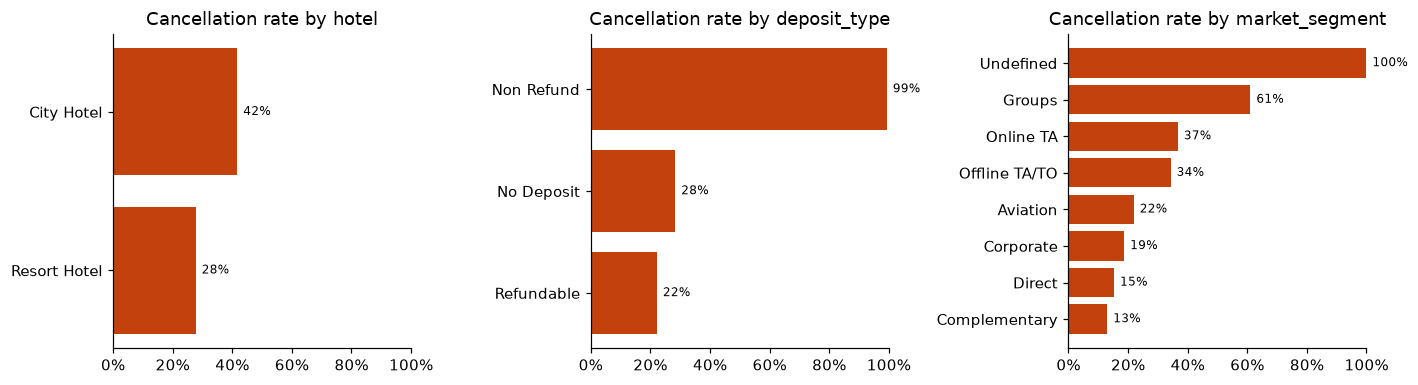

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, column in zip(axes, ["hotel", "deposit_type", "market_segment"], strict=True):
    rates = raw.groupby(column)[TARGET].mean().sort_values()
    ax.barh(rates.index, rates.values, color=CANCEL)
    ax.set_xlim(0, 1)
    ax.set_title(f"Cancellation rate by {column}")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    for y, value in enumerate(rates.values):
        ax.text(value + 0.02, y, f"{value:.0%}", va="center", fontsize=8)
plt.tight_layout()

### Lead time and the calendar

Bookings made far in advance cancel much more often. The rate also moves over time, which is
why a random train/test split is misleading here.

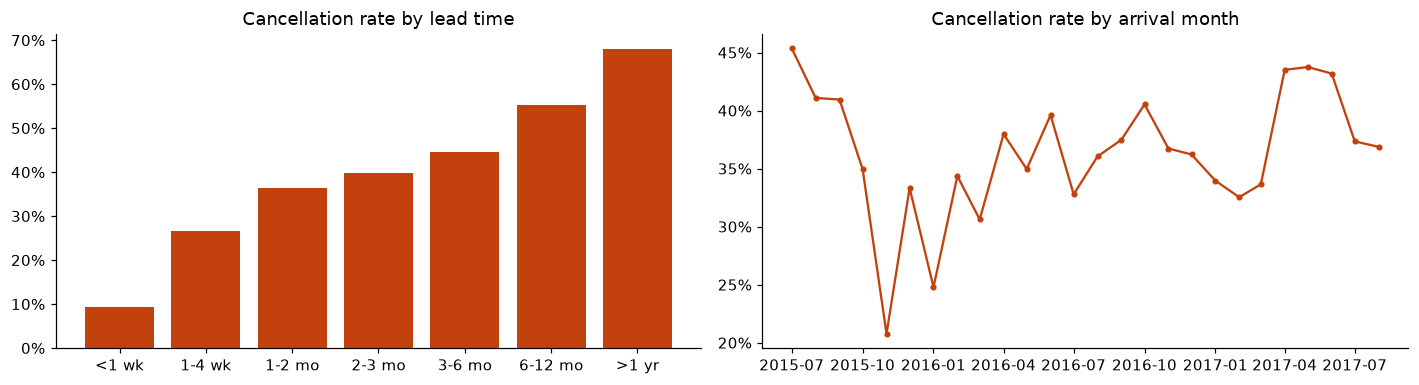

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.6))

bins = [0, 7, 30, 60, 90, 180, 365, 800]
labels = ["<1 wk", "1-4 wk", "1-2 mo", "2-3 mo", "3-6 mo", "6-12 mo", ">1 yr"]
by_lead = raw.groupby(pd.cut(raw.lead_time, bins, labels=labels, right=False), observed=True)
ax1.bar(labels, by_lead[TARGET].mean(), color=CANCEL)
ax1.set_title("Cancellation rate by lead time")
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

monthly = raw.set_index("arrival_date")[TARGET].resample("MS").mean()
ax2.plot(monthly.index, monthly.values, color=CANCEL, marker="o", markersize=3)
ax2.set_title("Cancellation rate by arrival month")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()

## 2. Leakage and the split

Two choices make the reported score honest:

- **Drop leaking columns.** `reservation_status`, `reservation_status_date`, `assigned_room_type`
  and `booking_changes` are only known at check-in or after a cancellation.
- **Split by date.** Train on older arrivals and test on newer ones, as the model will be used.

To see how much these matter, train the same quick model three ways and compare test ROC-AUC.
`reservation_status` is left out even from the "leaky" version, because it *is* the answer.

In [5]:
def quick_auc(train, test, numerical, categorical):
    pipe = Pipeline(
        [
            ("prep", build_preprocessor(numerical, categorical, min_category_frequency=50)),
            ("model", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=8, n_jobs=-1)),
        ]
    )
    pipe.fit(train.drop(columns=[TARGET]), train[TARGET])
    return roc_auc_score(test[TARGET], pipe.predict_proba(test.drop(columns=[TARGET]))[:, 1])


data = raw.drop(columns=["reservation_status", "reservation_status_date", "arrival_date"])
leaky_num = NUMERICAL + ["booking_changes"]
leaky_cat = CATEGORICAL + ["assigned_room_type"]

random_train, random_test = train_test_split(
    data, test_size=0.2, stratify=data[TARGET], random_state=42
)
ordered = data.loc[arrival_dates(data).sort_values(kind="stable").index]
cut = int(len(ordered) * 0.8)
time_train, time_test = ordered.iloc[:cut], ordered.iloc[cut:]

results = pd.DataFrame(
    [
        (
            "Random split + leaky columns",
            quick_auc(random_train, random_test, leaky_num, leaky_cat),
        ),
        ("Random split, no leakage", quick_auc(random_train, random_test, NUMERICAL, CATEGORICAL)),
        (
            "Time split, no leakage (project)",
            quick_auc(time_train, time_test, NUMERICAL, CATEGORICAL),
        ),
    ],
    columns=["setup", "test ROC-AUC"],
).set_index("setup")
results.round(3)

,test ROC-AUC
setup,
Random split + leaky columns,0.954
"Random split, no leakage",0.948
"Time split, no leakage (project)",0.882


Two lessons:

- **The split matters most.** Switching from a random split to a time split drops the score from
  about 0.95 to about 0.88. A random split lets the model see bookings from the same weeks it is
  tested on, so it overstates how well it will do on future bookings.
- **The leaky columns add less than expected** (about +0.006 here), because the worst one,
  `reservation_status`, was already left out. They are still dropped, because the API could not
  know them when a booking is made.

This quick model trains on *all* training rows with fixed settings and scores slightly higher
than the production model (≈0.875). Production holds back the newest 15% of training rows for
early stopping and threshold tuning. A possible improvement is to choose the number of trees on
that slice, then refit on all training rows.

## 3. The production model on the test set

In [6]:
predictor = PredictionPipeline()
test = pd.read_csv(config.get_data_ingestion_config().test_path)
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET].to_numpy()
proba = predictor.predict(X_test)["cancel_probability"].to_numpy()

print(
    f"Model {predictor.version}, threshold {predictor.threshold:.3f}, {len(test):,} test bookings"
)
pd.Series(classification_metrics(y_test, proba, predictor.threshold)).round(3).to_frame("test")

Model v1, threshold 0.295, 23,878 test bookings


,test
roc_auc,0.875
pr_auc,0.834
brier,0.151
accuracy,0.793
precision,0.766
recall,0.711
f1,0.738
threshold,0.295


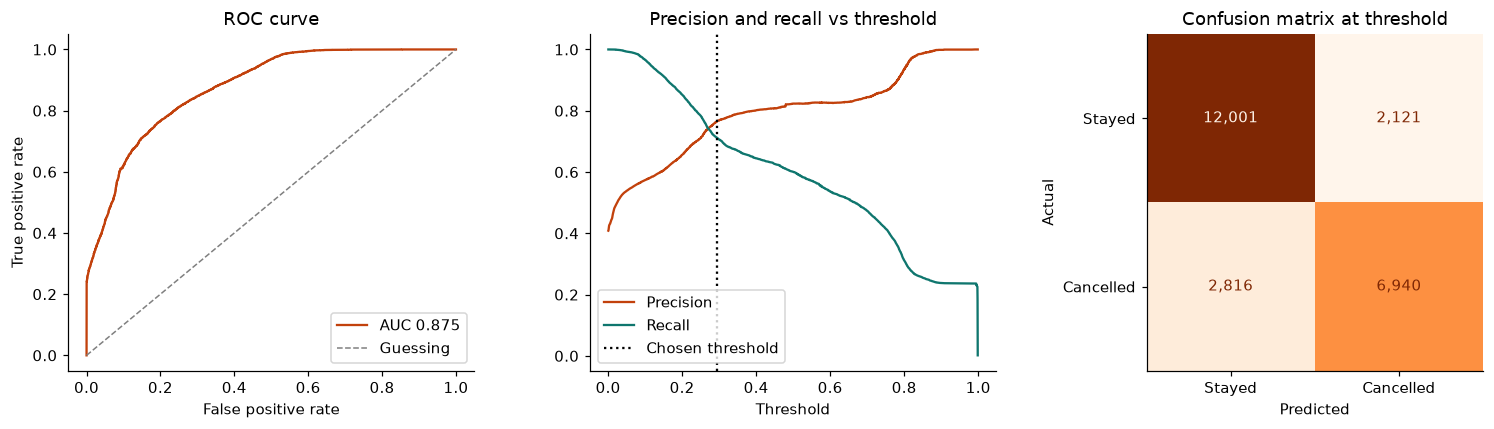

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

fpr, tpr, _ = roc_curve(y_test, proba)
axes[0].plot(fpr, tpr, color=CANCEL, label=f"AUC {roc_auc_score(y_test, proba):.3f}")
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1, label="Guessing")
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(loc="lower right")

precision, recall, thresholds = precision_recall_curve(y_test, proba)
axes[1].plot(thresholds, precision[:-1], color=CANCEL, label="Precision")
axes[1].plot(thresholds, recall[:-1], color=KEEP, label="Recall")
axes[1].axvline(predictor.threshold, color="black", linestyle=":", label="Chosen threshold")
axes[1].set(title="Precision and recall vs threshold", xlabel="Threshold")
axes[1].legend(loc="lower left")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    proba >= predictor.threshold,
    display_labels=["Stayed", "Cancelled"],
    cmap="Oranges",
    colorbar=False,
    ax=axes[2],
    values_format=",",
)
axes[2].set(title="Confusion matrix at threshold", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()

The threshold (≈0.29) was chosen on the validation slice to maximise F1, before the test set was
touched. Moving it right gives fewer, more certain flags (higher precision). Moving it left
catches more cancellations (higher recall). Pick the point that matches the cost of a missed
cancellation against the cost of a false alarm.

### Are the probabilities trustworthy?

A calibration check groups bookings by predicted probability and compares the prediction with
the real cancellation rate. Points on the diagonal mean "70% risk" really cancels about 70% of
the time.

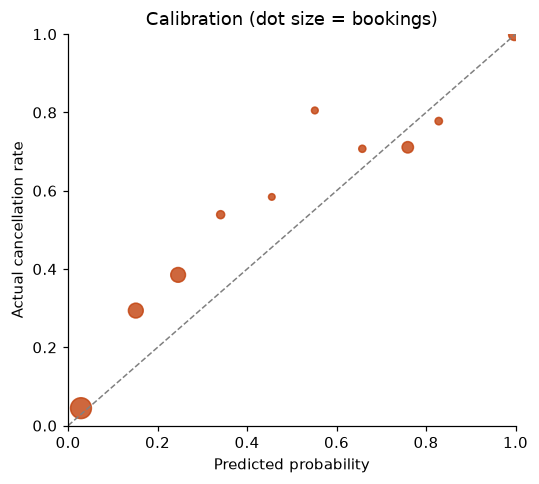

In [8]:
bands = pd.cut(proba, np.linspace(0, 1, 11), include_lowest=True)
calibration = pd.DataFrame({"predicted": proba, "actual": y_test}).groupby(bands, observed=True)
summary = calibration.mean().assign(bookings=calibration.size())

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
ax.scatter(summary.predicted, summary.actual, s=summary.bookings / 40, color=CANCEL, alpha=0.8)
ax.set(
    title="Calibration (dot size = bookings)",
    xlabel="Predicted probability",
    ylabel="Actual cancellation rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
plt.tight_layout()

The dots sit **above** the diagonal: on the test period, bookings cancel more often than the model
predicts. For example, bookings scored around 30% actually cancelled about half the time. This
matches the drift in section 5. The test months (spring and summer 2017) had a higher
cancellation rate than the training period (40.9% against 36.1%). The *ranking* is still good
(ROC-AUC 0.875), but the raw probabilities run low. Retraining on recent data, or adding a
calibration step, would fix this.

## 4. What drives the predictions

The prediction pipeline uses XGBoost's built-in TreeSHAP to split each prediction into
contributions per feature, in log-odds. One-hot columns are summed back into their source
feature. Averaging the absolute contributions over a sample of test bookings gives a global
importance ranking.

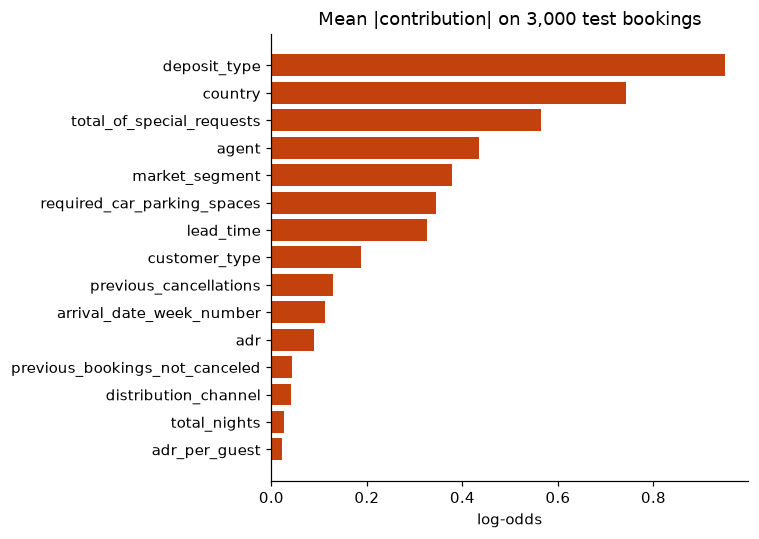

In [9]:
sample = X_test.sample(3000, random_state=0)
explanations = predictor.explain(sample, top_k=len(NUMERICAL) + len(CATEGORICAL))
contributions = pd.DataFrame(
    [{item["feature"]: item["contribution"] for item in row} for row in explanations]
)
importance = contributions.abs().mean().sort_values().tail(15)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance.values, color=CANCEL)
ax.set(title="Mean |contribution| on 3,000 test bookings", xlabel="log-odds")
plt.tight_layout()

### One booking, explained

Cancel probability 99.8% -> flagged (actual: cancelled)


,value,contribution
feature,,
deposit_type,Non Refund,6.0053
country,PRT,0.5582
customer_type,Transient,0.3657
market_segment,Offline TA/TO,-0.2441
total_of_special_requests,0,0.1904
lead_time,152,0.1834
agent,58,-0.1602
previous_cancellations,0,-0.0814


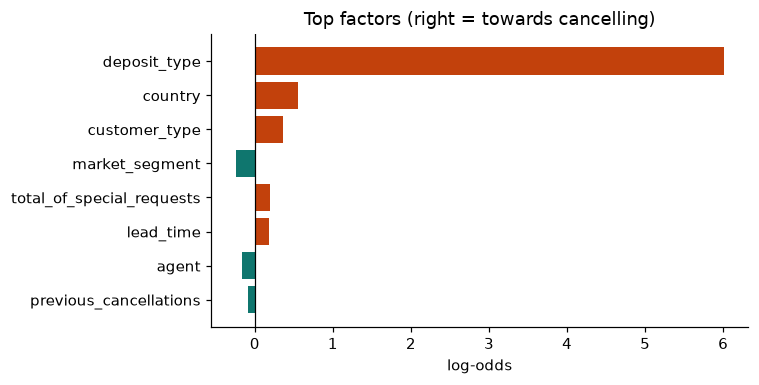

In [10]:
booking = X_test.iloc[[0]]
result = predictor.predict(booking).iloc[0]
print(
    f"Cancel probability {result.cancel_probability:.1%} -> "
    f"{'flagged' if result.will_cancel else 'not flagged'} (actual: "
    f"{'cancelled' if y_test[0] else 'stayed'})"
)

factors = pd.DataFrame(predictor.explain(booking, top_k=8)[0]).set_index("feature")
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = [CANCEL if c > 0 else KEEP for c in factors.contribution]
ax.barh(factors.index[::-1], factors.contribution[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Top factors (right = towards cancelling)", xlabel="log-odds")
plt.tight_layout()
factors

## 5. Drift between training and test

The same PSI check used by the API and the `hc-drift` command, applied to the test period. PSI
above 0.2 marks a feature as drifted.

6 of 30 features drifted; dataset drift: False


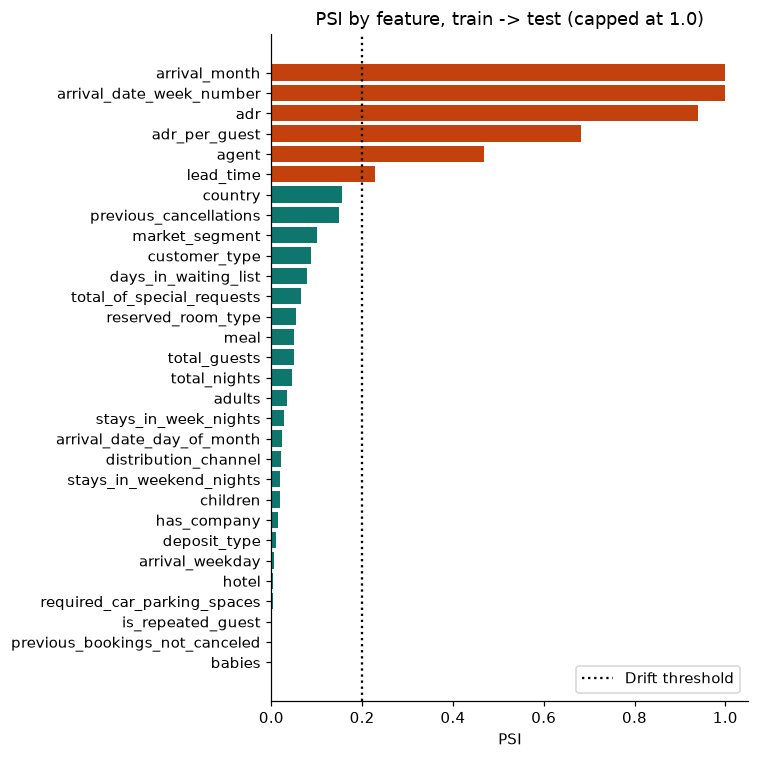

In [11]:
validation = config.get_data_validation_config()
train = pd.read_csv(config.get_data_ingestion_config().train_path)
features = FeatureEngineer()
profile = build_reference_profile(
    features.transform(train), NUMERICAL, CATEGORICAL, validation.n_bins
)
report = detect_drift(
    profile,
    features.transform(test),
    validation.psi_threshold,
    validation.drift_share_threshold,
)

psi = pd.Series({name: r["psi"] for name, r in report["features"].items()}).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(
    psi.index,
    psi.clip(upper=1.0),
    color=[CANCEL if v > validation.psi_threshold else KEEP for v in psi],
)
ax.axvline(validation.psi_threshold, color="black", linestyle=":", label="Drift threshold")
ax.set(title="PSI by feature, train -> test (capped at 1.0)", xlabel="PSI")
ax.legend(loc="lower right")
plt.tight_layout()
print(
    f"{len(report['drifted_features'])} of {report['n_features']} features drifted; "
    f"dataset drift: {report['dataset_drift']}"
)

Arrival month and week drift the most because the test period only covers April to August 2017.
Price (`adr`) and lead time also shifted. Together they explain most of the gap between the
validation score (≈0.91) and the test score (≈0.875).

## Summary

- On the newest 20% of bookings the model reaches **ROC-AUC ≈ 0.875** and **F1 ≈ 0.74**, without
  leaking columns and with a time-based split.
- Deposit type, country, lead time, special requests and market segment drive most predictions.
- The non-refundable deposit pattern is a quirk of this dataset. Check it before trusting the
  model on another hotel's data.
- Splitting by time matters more than any other choice. A random split would overstate the score
  by about 0.07 ROC-AUC.
- On the test period the probabilities run low (bookings cancel more often than predicted), in line
  with the seasonal drift. Retrain as new months arrive. The registry only promotes a new model if it
  beats the live one.
- Next improvements: refit on all training rows after early stopping, and calibrate probabilities.